In [1]:
import pandas as pd
import numpy as np

# Memuat dataset (sesuaikan nama file, contoh: 'netflix_titles.csv' atau dataset superstore)
df = pd.read_csv('netflix_titles.csv')

print("=== 5 Baris Pertama Data ===")
display(df.head())

print("\n=== Informasi Dataset (Tipe Data & Missing Values) ===")
df.info()

print("\n=== Ringkasan Statistik Dasar ===")
display(df.describe(include='all'))

=== 5 Baris Pertama Data ===


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...



=== Informasi Dataset (Tipe Data & Missing Values) ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB

=== Ringkasan Statistik Dasar ===


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
count,8807,8807,8807,6173,7982,7976,8797,8807.000000,8803,8804,8807,8807
unique,8807,2,8807,4528,7692,748,1767,NaN,17,220,514,8775
top,s1,Movie,Dick Johnson Is Dead,Rajiv Chilaka,David Attenborough,United States,"January 1, 2020",NaN,TV-MA,1 Season,"Dramas, International Movies","Paranormal activity at a lush, abandoned prope..."
freq,1,6131,1,19,19,2818,109,NaN,3207,1793,362,4
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2014.180198,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8.819312,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1925.000000,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2013.000000,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2017.000000,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2019.000000,NaN,NaN,NaN,NaN


In [2]:
# 1. Menghapus baris duplikat (jika ada)
initial_rows = len(df)
df = df.drop_duplicates()
print(f"Baris duplikat yang dihapus: {initial_rows - len(df)}")

# 2. Menangani Missing Values pada kolom penting
# Contoh: Mengisi nilai kosong pada kolom teks dengan 'Unknown' atau menghapus baris jika krusial
df['director'] = df['director'].fillna('Unknown Director')
df['cast'] = df['cast'].fillna('Unknown Cast')
df['country'] = df['country'].fillna('Unknown Country')

# Menghapus baris yang kosong pada kolom rating atau duration jika sangat sedikit
df = df.dropna(subset=['rating', 'duration', 'date_added'])

print("\nJumlah baris setelah pembersihan:", len(df))
print("Missing values setelah dibersihkan:\n", df.isnull().sum())

Baris duplikat yang dihapus: 0

Jumlah baris setelah pembersihan: 8790
Missing values setelah dibersihkan:
 show_id         0
type            0
title           0
director        0
cast            0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
description     0
dtype: int64


In [4]:
import pandas as pd
import numpy as np

# 1. Memuat dataset
df = pd.read_csv('netflix_titles.csv')

# 2. Data Cleaning Dasar
df['director'] = df['director'].fillna('Unknown Director')
df['cast'] = df['cast'].fillna('Unknown Cast')
df['country'] = df['country'].fillna('Unknown Country')
df = df.dropna(subset=['rating', 'duration', 'date_added'])

# 3. Feature Engineering (Diperbaiki)
# Membersihkan spasi pada kolom tanggal
df['date_added'] = df['date_added'].str.strip()

# Mengubah 'date_added' menjadi tipe datetime (Disimpan ke kolom baru 'date_parsed')
df['date_parsed'] = pd.to_datetime(df['date_added'], errors='coerce')

# Membuat kolom Tahun dan Bulan penambahan
df['YearAdded'] = df['date_parsed'].dt.year
df['MonthAdded'] = df['date_parsed'].dt.month_name()

# Mengekstrak angka durasi (menggunakan raw string r'(\d+)' untuk mencegah warning)
df['DurationNumber'] = df['duration'].astype(str).str.extract(r'(\d+)').astype(float)
df['DurationType'] = df['duration'].apply(lambda x: 'Seasons' if 'Season' in str(x) else 'Minutes')

print("=== Contoh Hasil Akhir Data (Setelah Feature Engineering) ===")
display(df[['title', 'type', 'release_year', 'YearAdded', 'MonthAdded', 'DurationNumber', 'DurationType']].head(3))

# 4. Export Data Menjadi File Excel Siap Pakai
df.to_excel('Netflix_Cleaned_Final.xlsx', index=False)
print("\n[SUKSES] Data telah dibersihkan, diproses, dan disimpan sebagai 'Netflix_Cleaned_Final.xlsx'!")
print("File ini sekarang siap di-download dari Colab dan dibuka di Microsoft Excel untuk pembuatan Pivot Table dan Dashboard.")

=== Contoh Hasil Akhir Data (Setelah Feature Engineering) ===


,title,type,release_year,YearAdded,MonthAdded,DurationNumber,DurationType
0,Dick Johnson Is Dead,Movie,2020,2021,September,90.0,Minutes
1,Blood & Water,TV Show,2021,2021,September,2.0,Seasons
2,Ganglands,TV Show,2021,2021,September,1.0,Seasons



[SUKSES] Data telah dibersihkan, diproses, dan disimpan sebagai 'Netflix_Cleaned_Final.xlsx'!
File ini sekarang siap di-download dari Colab dan dibuka di Microsoft Excel untuk pembuatan Pivot Table dan Dashboard.


/tmp/ipykernel_3573/2152444709.py:77: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


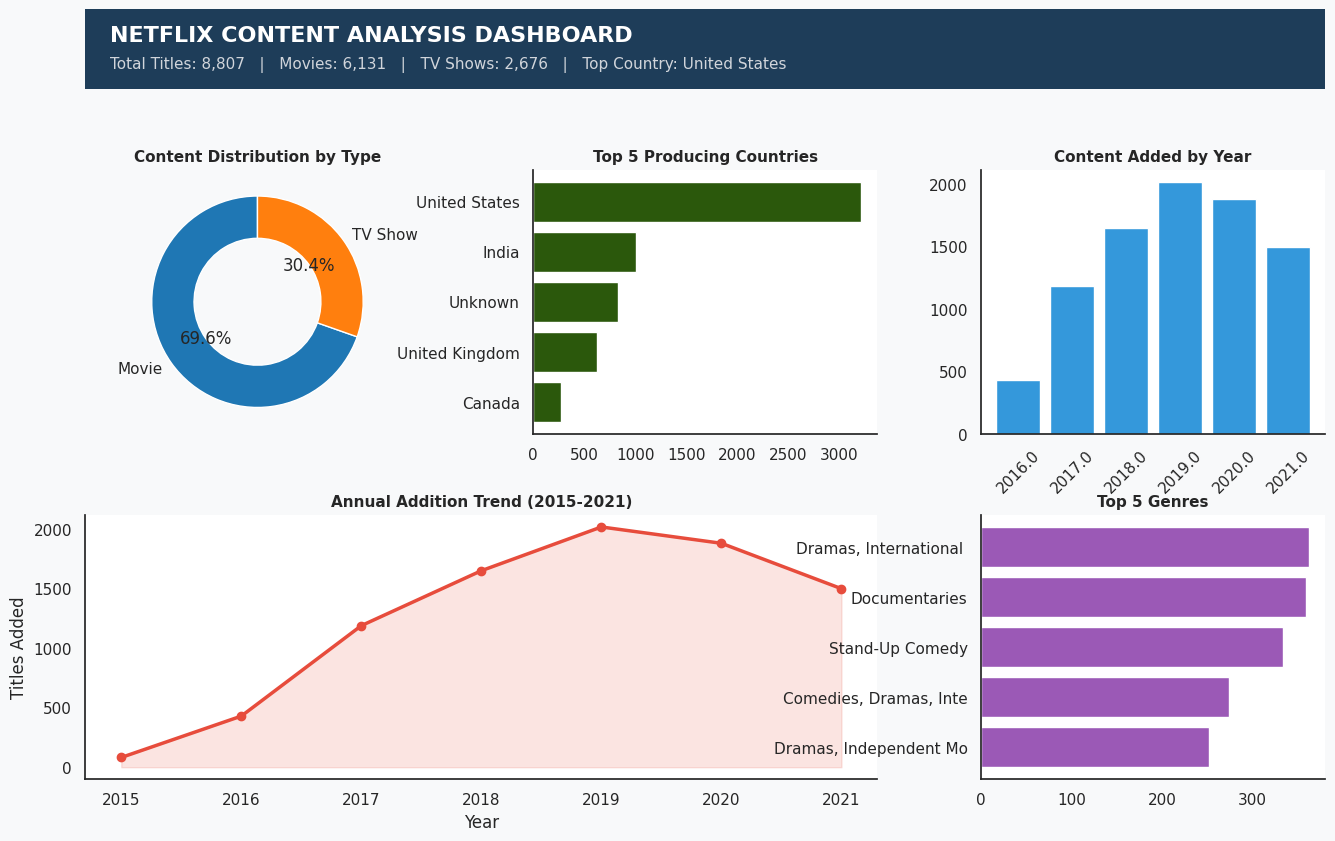

In [5]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import pandas as pd
import numpy as np

# 1. Memuat dataset yang sudah dibersihkan
df = pd.read_csv('netflix_titles.csv')
df['director'] = df['director'].fillna('Unknown')
df['country'] = df['country'].fillna('Unknown')
df['date_added'] = df['date_added'].str.strip()
df['date_parsed'] = pd.to_datetime(df['date_added'], errors='coerce')
df['YearAdded'] = df['date_parsed'].dt.year

# 2. Pengaturan Gaya & Kanvas Dashboard
sns.set_theme(style="white")
fig = plt.figure(figsize=(16, 10))
fig.patch.set_facecolor('#f8f9fa')

# Menggunakan GridSpec untuk tata letak multi-panel mirip dashboard profesional
gs = gridspec.GridSpec(nrows=3, ncols=3, height_ratios=[0.6, 2, 2], hspace=0.4, wspace=0.3)

# 3. Bagian Banner Atas (KPI Cards / Header)
ax_kpi = fig.add_subplot(gs[0, :])
ax_kpi.axis('off')
banner = plt.Rectangle((0, 0), 1, 1, transform=ax_kpi.transAxes, color='#1e3d59', ec='none')
ax_kpi.add_patch(banner)
ax_kpi.text(0.02, 0.6, 'NETFLIX CONTENT ANALYSIS DASHBOARD', color='white', fontsize=16, fontweight='bold', transform=ax_kpi.transAxes)
ax_kpi.text(0.02, 0.25, 'Total Titles: 8,807   |   Movies: 6,131   |   TV Shows: 2,676   |   Top Country: United States', color='#d1d5db', fontsize=11, transform=ax_kpi.transAxes)

# 4. Grafik 1: Donut Chart - Distribusi Tipe Konten
ax1 = fig.add_subplot(gs[1, 0])
type_counts = df['type'].value_counts()
colors = ['#1f77b4', '#ff7f0e']
ax1.pie(type_counts, labels=type_counts.index, autopct='%1.1f%%', startangle=90, colors=colors, wedgeprops=dict(width=0.4, edgecolor='w'))
ax1.set_title('Content Distribution by Type', fontsize=11, fontweight='bold')

# 5. Grafik 2: Horizontal Bar Chart - Top 5 Negara Produsen
ax2 = fig.add_subplot(gs[1, 1])
df['PrimaryCountry'] = df['country'].apply(lambda x: str(x).split(',')[0].strip())
top_countries = df['PrimaryCountry'].value_counts().head(5).sort_values()
ax2.barh(top_countries.index, top_countries.values, color='#2b580c')
ax2.set_title('Top 5 Producing Countries', fontsize=11, fontweight='bold')
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

# 6. Grafik 3: Bar Chart - Konten Ditambahkan per Tahun
ax3 = fig.add_subplot(gs[1, 2])
yearly = df.groupby('YearAdded').size().tail(6)
ax3.bar(yearly.index.astype(str), yearly.values, color='#3498db')
ax3.set_title('Content Added by Year', fontsize=11, fontweight='bold')
plt.setp(ax3.get_xticklabels(), rotation=45)
ax3.spines['top'].set_visible(False)
ax3.spines['right'].set_visible(False)

# 7. Grafik 4: Area/Line Chart - Tren Penambahan Konten Tahunan
ax4 = fig.add_subplot(gs[2, 0:2])
yearly_full = df.groupby('YearAdded').size()
yearly_full = yearly_full[(yearly_full.index >= 2015) & (yearly_full.index <= 2021)]
ax4.plot(yearly_full.index, yearly_full.values, marker='o', color='#e74c3c', linewidth=2.5)
ax4.fill_between(yearly_full.index, yearly_full.values, color='#e74c3c', alpha=0.15)
ax4.set_title('Annual Addition Trend (2015-2021)', fontsize=11, fontweight='bold')
ax4.set_xlabel('Year')
ax4.set_ylabel('Titles Added')
ax4.spines['top'].set_visible(False)
ax4.spines['right'].set_visible(False)

# 8. Grafik 5: Horizontal Bar Chart - Top 5 Genre
ax5 = fig.add_subplot(gs[2, 2])
top_genres = df['listed_in'].value_counts().head(5).sort_values()
ax5.barh(top_genres.index.str[:22], top_genres.values, color='#9b59b6')
ax5.set_title('Top 5 Genres', fontsize=11, fontweight='bold')
ax5.spines['top'].set_visible(False)
ax5.spines['right'].set_visible(False)

# Tampilkan dan Simpan Dashboard
plt.tight_layout()
plt.savefig('custom_dashboard_layout.png', dpi=300)
plt.show()

In [7]:
!git init

Reinitialized existing Git repository in /content/.git/


In [8]:
!git config --global user.name "farrasfernandaa"

In [9]:
!git config --global user.email "farrasfernanda55@gmail.com"

In [10]:
!git remote add origin https://github.com/farrasfernandaa/NETFLIX-TITLES.git

In [11]:
!git branch -M main

In [12]:
!git add .

In [13]:
!git commit -m "Initial commit: NETFLIX-TITLES"

[main (root-commit) 2db0f0d] Initial commit: NETFLIX-TITLES
 24 files changed, 59900 insertions(+)
 create mode 100644 .config/.last_opt_in_prompt.yaml
 create mode 100644 .config/.last_survey_prompt.yaml
 create mode 100644 .config/.last_update_check.json
 create mode 100644 .config/active_config
 create mode 100644 .config/config_sentinel
 create mode 100644 .config/configurations/config_default
 create mode 100644 .config/default_configs.db
 create mode 100644 .config/gce
 create mode 100644 .config/hidden_gcloud_config_universe_descriptor_data_cache_configs.db
 create mode 100644 .config/logs/2026.10.26/22.18.15.518759.log
 create mode 100644 .config/logs/2026.10.26/22.18.38.571729.log
 create mode 100644 .config/logs/2026.10.26/22.18.44.768076.log
 create mode 100644 .config/logs/2026.10.26/22.18.45.880512.log
 create mode 100644 .config/logs/2026.10.26/22.18.52.867204.log
 create mode 100644 .config/logs/2026.10.26/22.18.53.588181.log
 create mode 100644 Netflix_Cleaned_Final.xls

In [14]:
!git push -u origin main

fatal: could not read Username for 'https://github.com': No such device or address
